Graph with 5 nodes and 7 edges
Hamgiin bogino zam: ['Darkhan', 'Erdenet', 'Selenge', 'Khentii']
Hamgiin bogino zamiin urt: 3.67


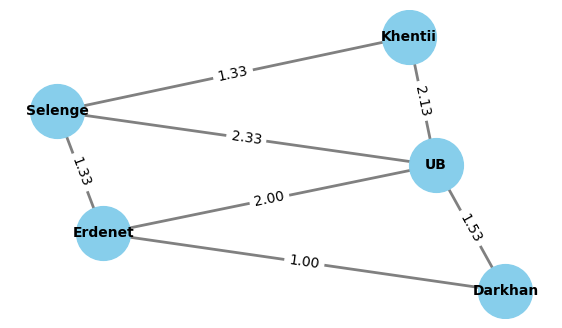

In [1]:
import networkx as nx
import matplotlib.pyplot as plt

cities_graph = nx.Graph()

# 5 - hangaiin muu shoroo
# 4 - arai deer shoroo
# 3 - nuhtei aspalt
# 2 - aspalt
# 1 - hangaiin sain aspalt

edges = [
    ('UB', 'Darkhan', {'distance': 230/150, 'difficulty': 1}),
    ('Darkhan', 'Erdenet', {'distance': 150/150, 'difficulty': 1}),
    ('UB', 'Erdenet', {'distance': 300/150, 'difficulty': 3}),
    ('Erdenet', 'Selenge', {'distance': 200/150, 'difficulty': 5}),
    ('UB', 'Selenge', {'distance': 350/150, 'difficulty': 4}),
    ('Selenge', 'Khentii', {'distance': 200/150, 'difficulty': 5}),
    ('UB', 'Khentii', {'distance': 320/150, 'difficulty': 1})
]

cities_graph.add_edges_from(edges)
print(cities_graph)

for start_node, stop_node, data in cities_graph.edges(data=True):
    data['composite_weight'] = 0.4 * data['distance'] + 0.6 * data['difficulty']

short_path = nx.shortest_path(cities_graph, source='Darkhan', target='Khentii', weight='distance')
short_path_len = nx.shortest_path_length(cities_graph, source='Darkhan', target='Khentii', weight='distance')

print(f"Hamgiin bogino zam: {short_path}")
print(f"Hamgiin bogino zamiin urt: {short_path_len:.2f}")  


plt.figure(figsize=(7, 4))
pos = nx.spring_layout(cities_graph, seed=42)

nx.draw_networkx_nodes(cities_graph, pos, node_size=1500, node_color='skyblue')
nx.draw_networkx_edges(cities_graph, pos, width=2, edge_color='gray')
nx.draw_networkx_labels(cities_graph, pos, font_size=10, font_family='sans-serif', font_weight='bold')

raw_edge_labels = nx.get_edge_attributes(cities_graph, 'distance')
formatted_edge_labels = {edge: f"{val:.2f}" for edge, val in raw_edge_labels.items()}

nx.draw_networkx_edge_labels(cities_graph, pos, edge_labels=formatted_edge_labels)

plt.axis('off')
plt.show()

## Лаборатори 4: Монгол улсын шилэн кабелийн сүлжээний загварчлал

Дээрх cell-д 5 хотын жижиг граф дээр `distance`, `difficulty`, `composite_weight`-ийг тооцож хамгийн богино замыг олсон.
Энд тэр графыг **Монгол улсын бодит газрын зураг дээр 22 хотын сүлжээ** болгон өргөтгөнө.

Кабелийг шулуунаар татахгүй. Газрын зургийг 5 км орчим нүдтэй торонд хувааж, нүд бүрт рельефийн **өртөг** өгсөн.

| Рельеф | Өртгийн үржвэр | Эх сурвалж |
| --- | --- | --- |
| Тал хээр, говь | 1.0 | |
| Уулархаг бүс | 2.0 | Natural Earth-ийн Алтай, Хангай, Хэнтийн нурууны хил |
| Ой (тайга) | 3.0 | Гараар тэмдэглэсэн ойролцоо бүс, дараа нь жинхэнэ өгөгдлөөр солино |
| Нуур | татах боломжгүй | Natural Earth-ийн нууруудын хил |

Хоёр хотын хоорондох кабелийн зам нь энэ торон дээрх **хамгийн бага өртөгтэй зам** байна. Тиймээс зам нь ой, уулыг тойрч гарна.

In [2]:
# Шаардлагатай сан (нэг удаа): pip install numpy scipy shapely networkx matplotlib

import json, math, os, itertools, urllib.request
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import dijkstra
from scipy.spatial import cKDTree
from shapely.geometry import shape, mapping, LineString
import shapely

plt.rcParams['font.family'] = 'DejaVu Sans'   # Кирилл, Ө, Ү үсгийг дэмждэг
plt.rcParams['figure.dpi'] = 110

### 1. Монгол улсын газрын зургийн өгөгдөл
Улсын хил, аймгийн хил, нуур, уулсын хилийг Natural Earth-ээс авна. Эхний удаа ажиллуулахад татаж аваад `data/mongolia_geo.json` гэсэн жижиг файл болгон хадгална. Дараа нь татахгүй.

In [3]:
DATA_DIR = 'data'
GEO_FILE = os.path.join(DATA_DIR, 'mongolia_geo.json')
NE_URL = 'https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/'
MOUNTAIN_NAMES = ['Hentiyn Mts.', 'Hangayn Mts.', 'ALTAY MOUNTAINS', 'Tannu-Ola Ra.']


def build_geo_cache():
    """Natural Earth-ээс зөвхөн Монголын хэсгийг салгаж жижиг файл болгоно."""
    os.makedirs(DATA_DIR, exist_ok=True)

    def load(name):
        path = os.path.join(DATA_DIR, name + '.geojson')
        if not os.path.exists(path):
            print('Татаж байна:', name)
            urllib.request.urlretrieve(NE_URL + name + '.geojson', path)
        with open(path, encoding='utf-8') as f:
            data = json.load(f)
        os.remove(path)                      # том түр файлыг устгана
        return data['features']

    country = next(shape(f['geometry']) for f in load('ne_10m_admin_0_countries')
                   if f['properties']['ADMIN'] == 'Mongolia')
    simp = lambda g: g.simplify(0.004)
    out = {
        'country': mapping(simp(country)),
        'aimags': [mapping(simp(shape(f['geometry']))) for f in load('ne_10m_admin_1_states_provinces')
                   if f['properties'].get('adm0_a3') == 'MNG'],
        'lakes': [],
        'mountains': [],
    }
    for f in load('ne_10m_lakes'):
        part = shape(f['geometry']).intersection(country)
        if part.area > 0.003:
            out['lakes'].append(mapping(simp(part)))
    for f in load('ne_10m_geography_regions_polys'):
        if f['properties']['NAME'] in MOUNTAIN_NAMES:
            out['mountains'].append(mapping(simp(shape(f['geometry']).intersection(country))))
    with open(GEO_FILE, 'w', encoding='utf-8') as f:
        json.dump(out, f)


if not os.path.exists(GEO_FILE):
    build_geo_cache()

with open(GEO_FILE, encoding='utf-8') as f:
    geo = json.load(f)
COUNTRY = shape(geo['country'])
AIMAGS = [shape(g) for g in geo['aimags']]
LAKES = [shape(g) for g in geo['lakes']]
MOUNTAINS = [shape(g) for g in geo['mountains']]
print(f'Улс 1, аймаг {len(AIMAGS)}, нуур {len(LAKES)}, уулын бүс {len(MOUNTAINS)}')

Улс 1, аймаг 22, нуур 14, уулын бүс 4


### 2. 22 зангилаа (хот) ба ойн бүс
Зангилааны түлхүүр нь таны кодын нэрийг (`UB`, `Darkhan`, ...) хэвээр хадгалсан. Дэлгэцэнд монгол нэрээр харуулна.

In [4]:
# түлхүүр: (өргөрөг, уртраг, монгол нэр)
CITIES = {
    'UB': (47.92, 106.92, 'Улаанбаатар'), 'Darkhan': (49.49, 105.92, 'Дархан'),
    'Erdenet': (49.03, 104.04, 'Эрдэнэт'), 'Selenge': (50.23, 106.21, 'Сэлэнгэ'),
    'Khentii': (47.31, 110.65, 'Хэнтий'), 'Sainshand': (44.89, 110.12, 'Сайншанд'),
    'Ulaangom': (49.98, 92.07, 'Улаангом'), 'Murun': (49.64, 100.16, 'Мөрөн'),
    'Bulgan': (48.81, 103.53, 'Булган'), 'Bayankhongor': (46.19, 100.72, 'Баянхонгор'),
    'Arvaikheer': (46.26, 102.78, 'Арвайхээр'), 'Mandalgovi': (45.76, 106.27, 'Мандалговь'),
    'Dalanzadgad': (43.57, 104.42, 'Даланзадгад'), 'Choibalsan': (48.07, 114.53, 'Чойбалсан'),
    'Olgii': (48.97, 89.96, 'Өлгий'), 'Khovd': (48.01, 91.64, 'Ховд'),
    'Altai': (46.37, 96.26, 'Алтай'), 'Tsetserleg': (47.48, 101.45, 'Цэцэрлэг'),
    'Zuunmod': (47.71, 106.95, 'Зуунмод'), 'BaruunUrt': (46.68, 113.28, 'Баруун-Урт'),
    'Uliastai': (47.74, 96.85, 'Улиастай'), 'Choir': (46.37, 108.36, 'Чойр'),
}
mn = lambda n: CITIES[n][2]

# Ойн бүс (уртраг, өргөрөг). Эдгээр нь ОЙРОЛЦОО гараар тэмдэглэсэн хил.
# Жинхэнэ өгөгдөл (ESA WorldCover, Hansen Global Forest Change, OSM landuse=forest)-өөр солиход бэлэн.
FOREST_ZONES = {
    'Хөвсгөлийн тайга':  [(98.0, 50.3), (98.2, 51.8), (102.4, 51.8), (102.2, 50.4), (100.9, 50.0), (99.2, 50.0)],
    'Хангайн хойд бэл':  [(97.6, 48.7), (98.4, 49.6), (101.6, 49.6), (103.3, 49.3), (102.9, 48.4), (100.5, 48.3)],
    'Сэлэнгийн ой':      [(103.9, 49.7), (104.2, 50.45), (107.8, 50.45), (107.6, 49.7)],
    'Хэнтийн ой':        [(107.0, 48.3), (107.3, 49.5), (110.6, 49.7), (111.9, 48.9), (110.3, 48.1)],
}
from shapely.geometry import Polygon
FORESTS = [Polygon(p).intersection(COUNTRY) for p in FOREST_ZONES.values()]

# Рельефийн өртгийн үржвэр: 0 тал, 1 уул, 2 ой, 3 нуур (татах боломжгүй)
TERRAIN_NAMES = ['Тал хээр, говь', 'Уулархаг бүс', 'Ой (тайга)', 'Нуур (татахгүй)']
TERRAIN_MULT = np.array([1.0, 2.0, 3.0, np.inf])
TERRAIN_COLORS = ['#efe8d2', '#cfae82', '#86b777', '#8ecae6']

### 3. Өртгийн тор
Улсыг 0.05° (ойролцоогоор 5 км) нүдэнд хуваагаад нүд бүрт рельефийн ангилал оноож байна.

In [5]:
RES = 0.05
lon0, lon1, lat0, lat1 = 87.5, 120.1, 41.5, 52.3
lons = np.arange(lon0, lon1, RES)
lats = np.arange(lat0, lat1, RES)
LON, LAT = np.meshgrid(lons, lats)          # хэлбэр (өргөрөг, уртраг)
ny, nx_ = LON.shape


def mask(geom):
    return shapely.contains_xy(geom, LON.ravel(), LAT.ravel()).reshape(LON.shape)


inside = mask(COUNTRY.buffer(0.03))
cat = np.zeros(LON.shape, dtype=np.int8)
for g in MOUNTAINS: cat[mask(g)] = 1
for g in FORESTS:   cat[mask(g)] = 2
for g in LAKES:     cat[mask(g.buffer(0.02))] = 3
mult = TERRAIN_MULT[cat]
mult[~inside] = np.inf
valid = np.isfinite(mult)
print(f'Тор {ny} x {nx_}, ашиглах боломжтой нүд: {valid.sum():,}')
for k, name in enumerate(TERRAIN_NAMES):
    print(f'  {name}: {(cat[inside] == k).mean() * 100:.1f}%')

Тор 216 x 652, ашиглах боломжтой нүд: 74,108
  Тал хээр, говь: 61.5%
  Уулархаг бүс: 27.6%
  Ой (тайга): 9.9%
  Нуур (татахгүй): 1.0%


### 4. Газрын зураг зурах функц

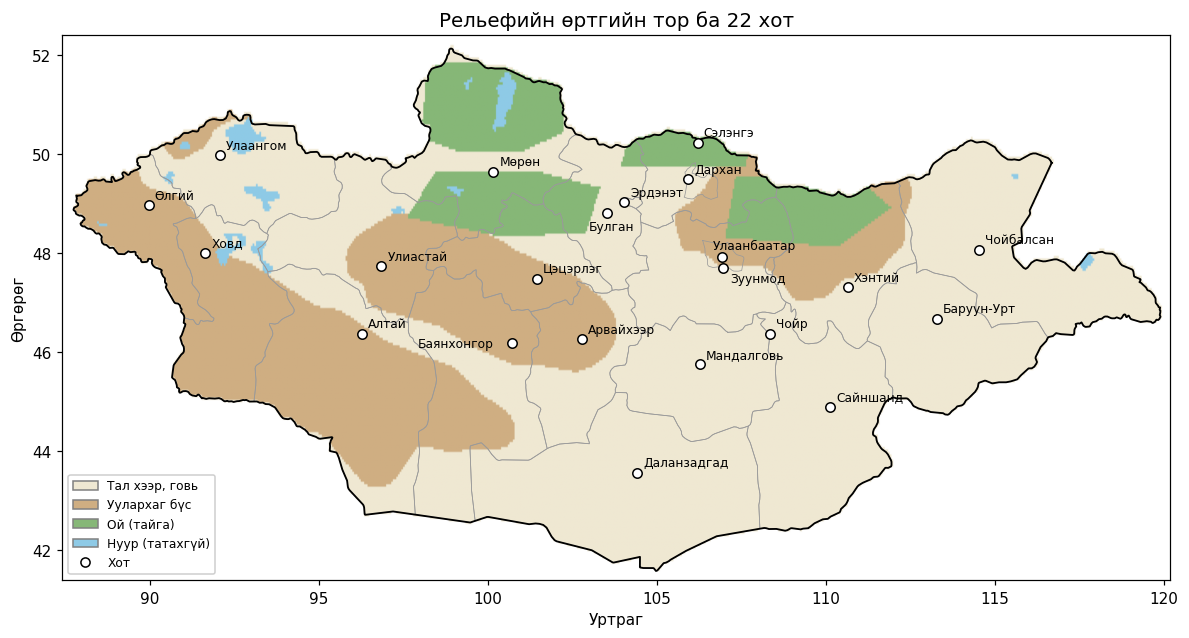

In [6]:
ASPECT = 1 / math.cos(math.radians(47))
LABEL_OFFSET = {'UB': (-6, 5), 'Zuunmod': (5, -10), 'Bulgan': (-12, -11), 'Bayankhongor': (-62, -3)}


def draw_geom(ax, g, **kw):
    for p in getattr(g, 'geoms', [g]):
        ax.plot(*p.exterior.xy, **kw)


def base_map(ax, title=''):
    img = np.ones(cat.shape + (3,))
    for k, col in enumerate(TERRAIN_COLORS):
        img[cat == k] = mcolors.to_rgb(col)
    img[~inside] = 1.0
    ax.imshow(img, origin='lower', aspect=ASPECT, zorder=0,
              extent=[lons[0] - RES / 2, lons[-1] + RES / 2, lats[0] - RES / 2, lats[-1] + RES / 2])
    for g in AIMAGS:
        draw_geom(ax, g, color='#9a9a9a', lw=0.5, zorder=1)
    draw_geom(ax, COUNTRY, color='black', lw=1.2, zorder=2)
    ax.set_xlim(87.4, 120.2); ax.set_ylim(41.4, 52.4)
    ax.set_xlabel('Уртраг'); ax.set_ylabel('Өргөрөг')
    ax.set_title(title, fontsize=13)


def draw_cities(ax, nodes=None, highlight=None):
    for n in (nodes or CITIES):
        lat, lon, name = CITIES[n]
        bad = highlight and n in highlight
        ax.scatter(lon, lat, s=38, c='#ffd6d6' if bad else 'white',
                   edgecolors='red' if bad else 'black', linewidths=1.6 if bad else 1, zorder=5)
        ax.annotate(name, (lon, lat), xytext=LABEL_OFFSET.get(n, (4, 4)), textcoords='offset points',
                    fontsize=8, zorder=6)


def terrain_legend(ax, line_color, line_label):
    items = [Patch(facecolor=c, edgecolor='grey', label=n) for c, n in zip(TERRAIN_COLORS, TERRAIN_NAMES)]
    if line_label == 'Хот':
        items.append(Line2D([0], [0], marker='o', color='w', markerfacecolor='white', markeredgecolor='black', label='Хот'))
    else:
        items.append(Line2D([0], [0], color=line_color, lw=3, label=line_label))
    ax.legend(handles=items, loc='lower left', fontsize=8, framealpha=0.95)


fig, ax = plt.subplots(figsize=(13, 6.8))
base_map(ax, 'Рельефийн өртгийн тор ба 22 хот')
draw_cities(ax)
terrain_legend(ax, 'white', 'Хот')
plt.show()

### 5. Хамгийн бага өртөгтэй кабелийн зам
22 хот бүрээс торон дээр Dijkstra ажиллуулж, хос бүрийн замыг олно. Зам нь ой, уулыг тойрч, боломжтой бол тал хээрээр гарна.

In [7]:
node_id = -np.ones(mult.shape, dtype=np.int64)
node_id[valid] = np.arange(valid.sum())
I, J = np.nonzero(valid)
OFFSETS = [(0, 1), (1, 0), (1, 1), (1, -1), (1, 2), (2, 1), (1, -2), (2, -1)]   # 16 чиглэл

rows, cols, costs = [], [], []
for di, dj in OFFSETS:
    NI, NJ = I + di, J + dj
    ok = (NI >= 0) & (NI < ny) & (NJ >= 0) & (NJ < nx_)
    ok[ok] &= node_id[NI[ok], NJ[ok]] >= 0
    a, b = node_id[I[ok], J[ok]], node_id[NI[ok], NJ[ok]]
    lat_mid = lats[I[ok]] + di * RES / 2
    km = np.hypot(di * RES * 110.57, dj * RES * 111.32 * np.cos(np.radians(lat_mid)))
    rows.append(a); cols.append(b)
    costs.append(km * (mult[I[ok], J[ok]] + mult[NI[ok], NJ[ok]]) / 2)
n_nodes = int(valid.sum())
GRID = coo_matrix((np.concatenate(costs), (np.concatenate(rows), np.concatenate(cols))),
                  shape=(n_nodes, n_nodes)).tocsr()

# хотыг хамгийн ойрын боломжтой нүдэнд холбоно
c47 = math.cos(math.radians(47))
tree = cKDTree(np.c_[lons[J] * c47, lats[I]])
city_cell = {n: int(tree.query([lon * c47, lat])[1]) for n, (lat, lon, _) in CITIES.items()}
names = list(CITIES)
dist, pred = dijkstra(GRID, directed=False, indices=[city_cell[n] for n in names], return_predecessors=True)
print('Хамгийн бага өртгийн замууд бодогдлоо')

Хамгийн бага өртгийн замууд бодогдлоо


In [8]:
def seg_km(lo1, la1, lo2, la2):
    return np.hypot((la2 - la1) * 110.57, (lo2 - lo1) * 111.32 * np.cos(np.radians((la1 + la2) / 2)))


def trace(src_idx, target):
    """Dijkstra-ийн predecessor-оор эх хотоос зорилт хүртэлх нүднүүдийг буцаана."""
    path = [city_cell[target]]
    while path[-1] != city_cell[names[src_idx]]:
        path.append(int(pred[src_idx][path[-1]]))
    return path[::-1]


def build_full_mesh():
    """Full Mesh: 22 хотын хос бүрт хамгийн бага өртөгтэй зам (231 кабель)."""
    G = nx.Graph()
    for n, (lat, lon, name) in CITIES.items():
        G.add_node(n, lat=lat, lon=lon, name_mn=name)
    for a, b in itertools.combinations(range(len(names)), 2):
        u, v = names[a], names[b]
        nodes = trace(a, v)
        xs, ys = lons[J[nodes]], lats[I[nodes]]
        seg = seg_km(xs[:-1], ys[:-1], xs[1:], ys[1:])
        seg_cat = cat[I[nodes[:-1]], J[nodes[:-1]]]
        km, cost = float(seg.sum()), float(dist[a][city_cell[v]])
        m = cost / km
        difficulty = float(np.clip(1 + 4 * (m - 1) / 2, 1, 5))       # таны 1..5 хэмжүүр
        route = list(LineString(np.c_[xs, ys]).simplify(0.02).coords)
        G.add_edge(u, v, distance_km=round(km, 1), cost_km=round(cost, 1),
                   forest_km=round(float(seg[seg_cat == 2].sum()), 1),
                   mountain_km=round(float(seg[seg_cat == 1].sum()), 1),
                   difficulty=round(difficulty, 2), distance=km / 150,
                   composite_weight=0.4 * (km / 150) + 0.6 * difficulty, route=route)
    return G


full = build_full_mesh()
print(f'Full Mesh: {full.number_of_nodes()} зангилаа, {full.number_of_edges()} кабель')
for u, v in [('UB', 'Darkhan'), ('UB', 'Khentii'), ('Murun', 'Tsetserleg')]:
    d = full[u][v]
    straight = float(seg_km(CITIES[u][1], CITIES[u][0], CITIES[v][1], CITIES[v][0]))
    print(f"{mn(u)} - {mn(v)}: шулуун {straight:.0f} км, кабелийн зам {d['distance_km']} км "
          f"(ой {d['forest_km']} км, уул {d['mountain_km']} км), хүндрэл {d['difficulty']}")

Full Mesh: 22 зангилаа, 231 кабель
Улаанбаатар - Дархан: шулуун 188 км, кабелийн зам 263.4 км (ой 0.0 км, уул 24.2 км), хүндрэл 1.15
Улаанбаатар - Хэнтий: шулуун 288 км, кабелийн зам 332.8 км (ой 0.0 км, уул 25.0 км), хүндрэл 1.12
Мөрөн - Цэцэрлэг: шулуун 257 км, кабелийн зам 494.7 км (ой 0.0 км, уул 26.7 км), хүндрэл 1.13


### 6. Алгоритмууд
MST (Prim), Bridge илрүүлэлт (Tarjan, `nx.bridges`), 2-Edge-Connected болгох нэмэлт кабель, кабель тасралтын симуляци.
MST болон нэмэлт кабелийг **рельефийн өртгөөр** (`cost_km`) сонгоно. Урт, RTT-г бодит уртаар (`distance_km`) тооцно.

In [9]:
FIBER_US_PER_KM = 5      # шилэн кабелд дохио ойролцоогоор 5 мкс/км


def total_km(G):   return sum(d['distance_km'] for *_, d in G.edges(data=True))
def total_cost(G): return sum(d['cost_km'] for *_, d in G.edges(data=True))


def build_mst(full, weight='cost_km'):                          # FR-2.1
    return nx.minimum_spanning_tree(full, weight=weight, algorithm='prim')


def find_bridges(G):                                            # FR-2.2
    return [tuple(e) for e in nx.bridges(G)]


def augment_to_2_edge_connected(full, tree, weight='cost_km'):  # FR-2.3
    """Нэмэх үед хамгийн олон bridge-ийг арилгах (өртөг / арилгасан bridge хамгийн бага) кабелийг давтан нэмнэ."""
    H = tree.copy()
    added = []
    while True:
        before = len(find_bridges(H))
        if before == 0:
            break
        best = None
        for u, v, d in full.edges(data=True):
            if H.has_edge(u, v):
                continue
            H.add_edge(u, v)
            gain = before - len(find_bridges(H))
            H.remove_edge(u, v)
            if gain > 0 and (best is None or d[weight] / gain < best[0]):
                best = (d[weight] / gain, u, v, d)
        _, u, v, d = best
        H.add_edge(u, v, **d)
        added.append((u, v))
    return H, added


def stats(G, base_km):
    km, bridges = total_km(G), find_bridges(G)
    lengths = dict(nx.all_pairs_dijkstra_path_length(G, weight='distance_km'))
    diameter = max(max(r.values()) for r in lengths.values())
    return {'edges': G.number_of_edges(), 'km': km, 'cost': total_cost(G),
            'overhead': (km / base_km - 1) * 100, 'bridges': len(bridges),
            'rtt_ms': 2 * diameter * FIBER_US_PER_KM / 1000,
            'fault_tolerant': nx.is_connected(G) and not bridges}


def simulate_cut(G, u, v):                                      # FR-3.1, FR-3.2
    H = G.copy()
    H.remove_edge(u, v)
    comps = sorted(nx.connected_components(H), key=lambda c: 'UB' not in c)   # төв нь Улаанбаатар
    res = {'connected': len(comps) == 1, 'isolated': sorted(n for c in comps[1:] for n in c)}
    if res['connected']:
        res['reroute'] = nx.shortest_path(H, u, v, weight='distance_km')
        res['reroute_km'] = nx.shortest_path_length(H, u, v, weight='distance_km')
    return res

### 7. Топологиуд ба харьцуулалт

In [10]:
mst = build_mst(full)
two, added = augment_to_2_edge_connected(full, mst)
topologies = {'MST': mst, '2-Edge-Connected': two, 'Full Mesh': full}
base = total_km(mst)

print(f"{'Топологи':18s}{'Кабель':>8s}{'Урт, км':>10s}{'Өртөг, км':>11s}{'MST-ээс':>9s}{'Bridge':>8s}{'RTT, мс':>9s}  1-Fault")
for name, G in topologies.items():
    s = stats(G, base)
    print(f"{name:18s}{s['edges']:8d}{s['km']:10.0f}{s['cost']:11.0f}{s['overhead']:8.1f}%{s['bridges']:8d}{s['rtt_ms']:9.1f}  {'Тийм' if s['fault_tolerant'] else 'Үгүй'}")

print(f"\nMST-ийн bridge ({len(find_bridges(mst))} кабель): MST нь модон бүтэцтэй тул бүх кабель bridge байна")
print(f"\n2-Edge болгохын тулд нэмсэн {len(added)} кабель:")
for u, v in added:
    d = two[u][v]
    print(f"  {mn(u)} - {mn(v)}: {d['distance_km']} км (ой {d['forest_km']} км, уул {d['mountain_km']} км)")

Топологи            Кабель   Урт, км  Өртөг, км  MST-ээс  Bridge  RTT, мс  1-Fault
MST                     21      4327       5056     0.0%      21     29.0  Үгүй
2-Edge-Connected        29      6944       8025    60.5%       0     23.0  Тийм
Full Mesh              231    166812     178811  3755.3%       0     19.8  Тийм

MST-ийн bridge (21 кабель): MST нь модон бүтэцтэй тул бүх кабель bridge байна

2-Edge болгохын тулд нэмсэн 8 кабель:
  Арвайхээр - Даланзадгад: 325.9 км (ой 0.0 км, уул 63.9 км)
  Сайншанд - Баруун-Урт: 320.4 км (ой 0.0 км, уул 0.0 км)
  Улаангом - Мөрөн: 594.4 км (ой 0.0 км, уул 0.0 км)
  Улаанбаатар - Чойр: 204.4 км (ой 0.0 км, уул 23.3 км)
  Өлгий - Ховд: 246.2 км (ой 0.0 км, уул 63.1 км)
  Хэнтий - Чойбалсан: 318.5 км (ой 0.0 км, уул 0.0 км)
  Эрдэнэт - Сэлэнгэ: 222.8 км (ой 53.1 км, уул 0.0 км)
  Мөрөн - Улиастай: 384.6 км (ой 0.0 км, уул 89.1 км)


### 8. Топологиуд газрын зураг дээр (FR-4.1)
MST улаан, 2-Edge цэнхэр, Full Mesh ногоон. Кабель ой, уулыг тойрч гарч байгааг харна уу.

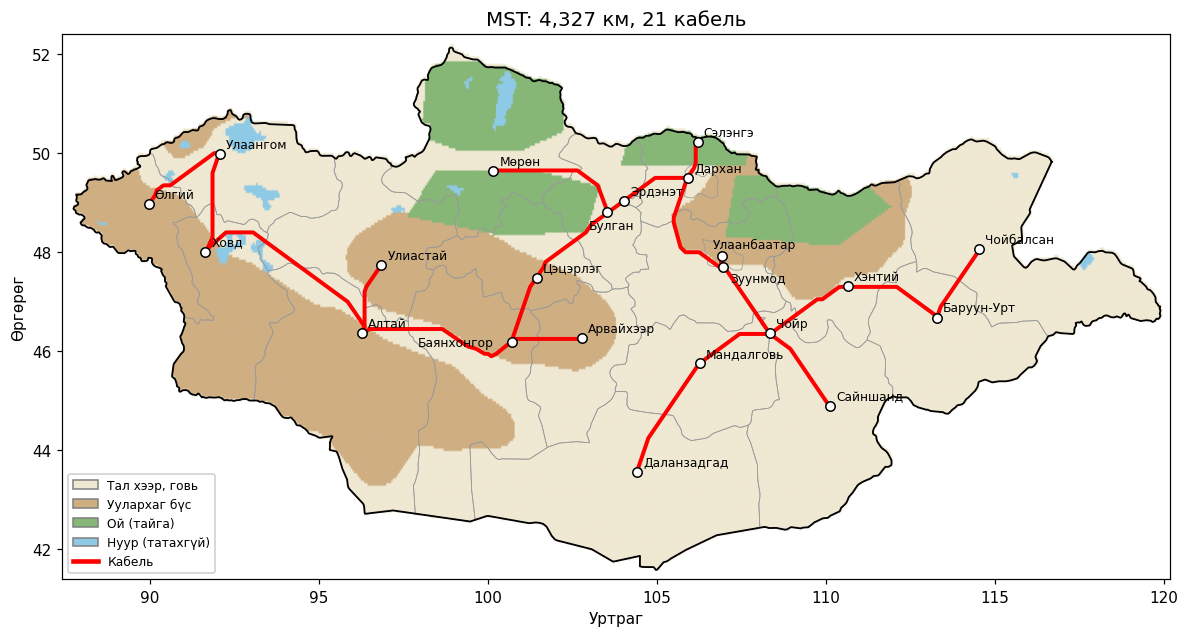

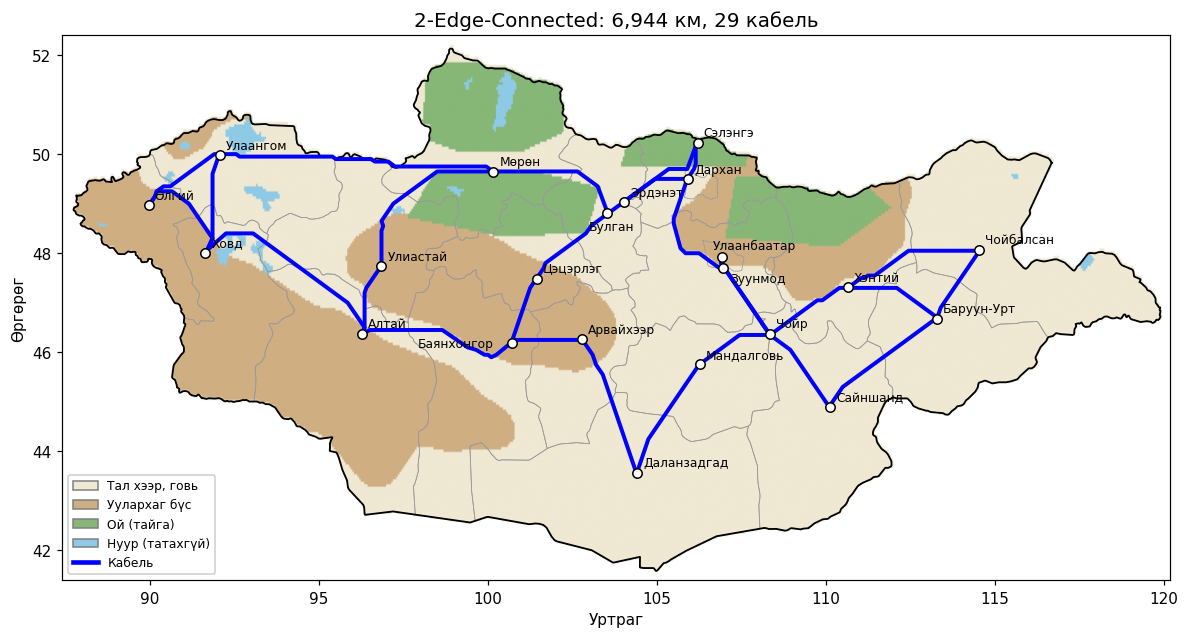

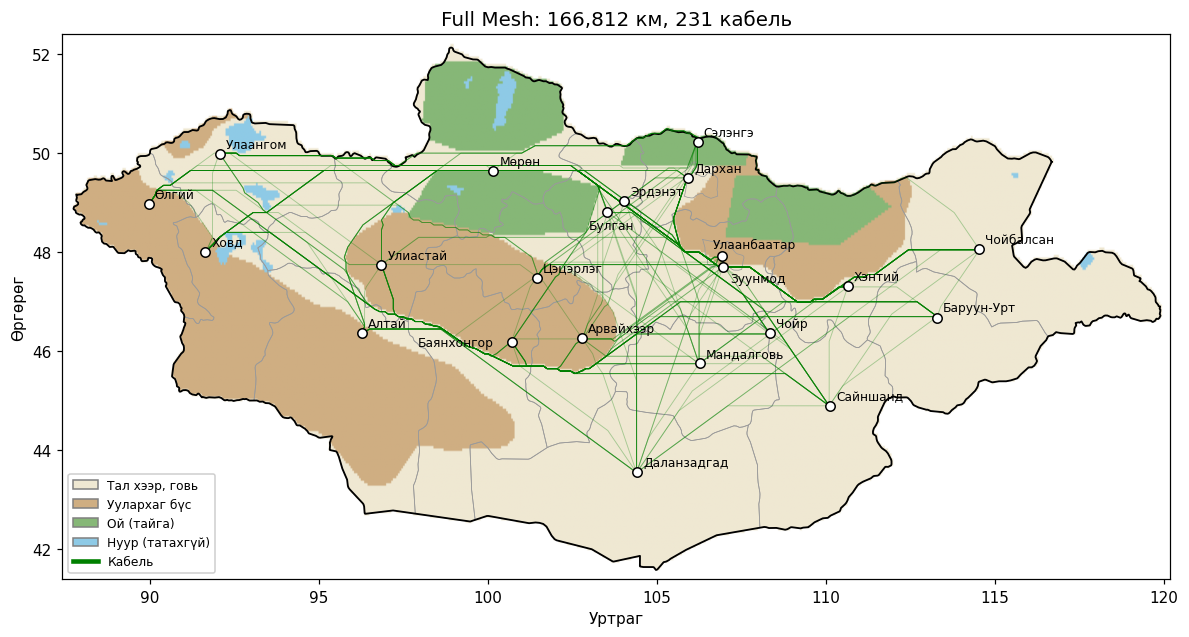

In [11]:
def draw_topology(G, color, title, lw=2.6, alpha=1.0):
    fig, ax = plt.subplots(figsize=(13, 6.8))
    base_map(ax, title)
    for u, v, d in G.edges(data=True):
        xs, ys = zip(*d['route'])
        ax.plot(xs, ys, color=color, lw=lw, alpha=alpha, solid_capstyle='round', zorder=3)
    draw_cities(ax)
    terrain_legend(ax, color, 'Кабель')
    plt.show()


draw_topology(mst, 'red', f'MST: {total_km(mst):,.0f} км, {mst.number_of_edges()} кабель')
draw_topology(two, 'blue', f'2-Edge-Connected: {total_km(two):,.0f} км, {two.number_of_edges()} кабель')
draw_topology(full, 'green', f'Full Mesh: {total_km(full):,.0f} км, {full.number_of_edges()} кабель', lw=0.6, alpha=0.3)

### 9. Тойрч татсан зам ба шулуун татсан замын харьцуулалт
MST-ийн кабелиуд шулуун татвал рельефийн өртөг хэд болох вэ? Тойрч татсан замтай харьцуулъя.

In [12]:
def straight_terrain_cost(u, v):
    """Хоёр хотыг шулуун татвал туулах рельефийн өртөг (нуур, улсын гадна нүдэнд 10 торгууль)."""
    (la1, lo1, _), (la2, lo2, _) = CITIES[u], CITIES[v]
    km = float(seg_km(lo1, la1, lo2, la2))
    t = np.linspace(0, 1, max(int(km / 2), 2))
    ii = np.clip(np.round((la1 + (la2 - la1) * t - lats[0]) / RES).astype(int), 0, ny - 1)
    jj = np.clip(np.round((lo1 + (lo2 - lo1) * t - lons[0]) / RES).astype(int), 0, nx_ - 1)
    m = np.where(np.isfinite(mult[ii, jj]), mult[ii, jj], 10.0)
    return km, float(m.mean() * km)


s_km = s_cost = 0
for u, v in mst.edges():
    km, cost = straight_terrain_cost(u, v)
    s_km += km; s_cost += cost
print(f"MST шулуун татвал : {s_km:8.0f} км, рельефийн өртөг {s_cost:8.0f} км")
print(f"MST тойрч татвал  : {total_km(mst):8.0f} км, рельефийн өртөг {total_cost(mst):8.0f} км")
print(f"Тойрсноор урт {(total_km(mst) / s_km - 1) * 100:+.1f}%, рельефийн өртөг {(total_cost(mst) / s_cost - 1) * 100:+.1f}%")

MST шулуун татвал :     4049 км, рельефийн өртөг     6084 км
MST тойрч татвал  :     4327 км, рельефийн өртөг     5056 км
Тойрсноор урт +6.9%, рельефийн өртөг -16.9%


### 10. Кабель тасралтын симуляци (FR-3.1, FR-3.2)

[MST] Зуунмод - Дархан кабель тасарлаа
  Улаанбаатараас тасарсан 13 зангилаа: Алтай, Арвайхээр, Баянхонгор, Булган, Дархан, Эрдэнэт, Ховд, Мөрөн, Өлгий, Сэлэнгэ, Цэцэрлэг, Улаангом, Улиастай


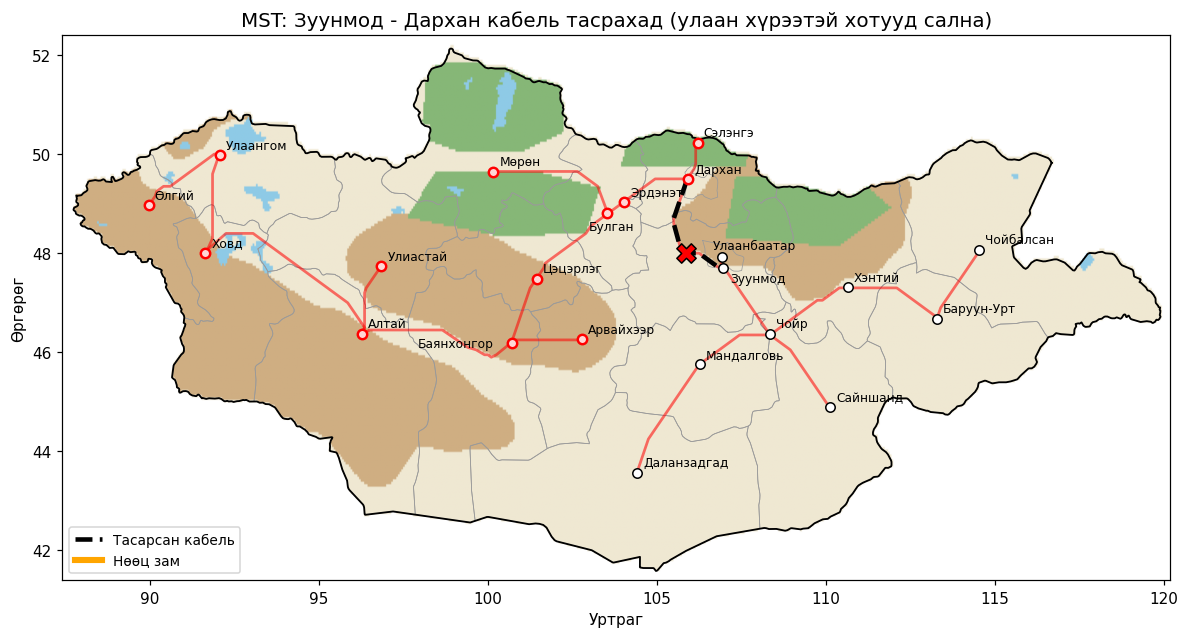

[2-Edge] Зуунмод - Дархан кабель тасарлаа
  Сүлжээ холбоотой хэвээр. Нөөц зам: Зуунмод > Чойр > Мандалговь > Даланзадгад > Арвайхээр > Баянхонгор > Цэцэрлэг > Булган > Эрдэнэт > Дархан (1710 км)


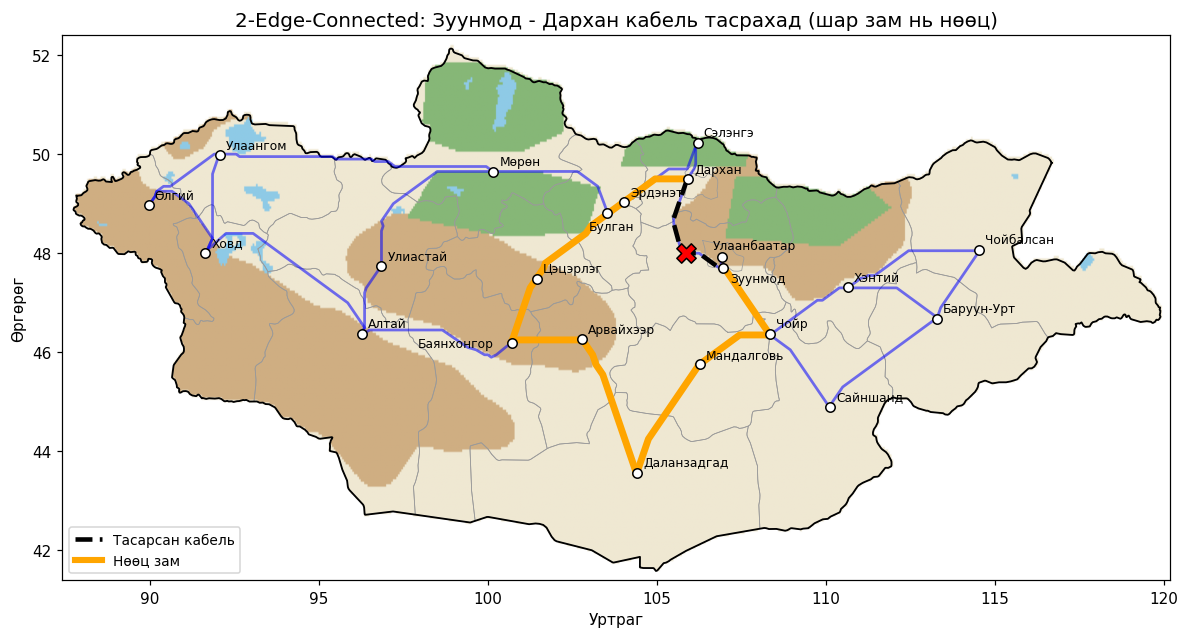

In [13]:
def report_cut(G, u, v, label):
    r = simulate_cut(G, u, v)
    print(f'[{label}] {mn(u)} - {mn(v)} кабель тасарлаа')
    if r['connected']:
        print(f"  Сүлжээ холбоотой хэвээр. Нөөц зам: {' > '.join(mn(n) for n in r['reroute'])} ({r['reroute_km']:.0f} км)")
    else:
        print(f"  Улаанбаатараас тасарсан {len(r['isolated'])} зангилаа: {', '.join(mn(n) for n in r['isolated'])}")
    return r


def draw_cut(G, u, v, color, title):
    r = simulate_cut(G, u, v)
    fig, ax = plt.subplots(figsize=(13, 6.8))
    base_map(ax, title)
    for a, b, d in G.edges(data=True):
        xs, ys = zip(*d['route'])
        ax.plot(xs, ys, color=color, lw=1.8, alpha=0.55, zorder=3)
    if r['connected']:
        for a, b in zip(r['reroute'], r['reroute'][1:]):
            xs, ys = zip(*G[a][b]['route'])
            ax.plot(xs, ys, color='orange', lw=4.5, zorder=4)
    xs, ys = zip(*G[u][v]['route'])
    ax.plot(xs, ys, color='black', lw=3, ls='--', zorder=5)
    ax.scatter(xs[len(xs) // 2], ys[len(ys) // 2], marker='X', s=160, c='red', edgecolors='black', zorder=6)
    draw_cities(ax, highlight=r['isolated'])
    items = [Line2D([0], [0], color='black', lw=3, ls='--', label='Тасарсан кабель'),
             Line2D([0], [0], color='orange', lw=4, label='Нөөц зам')]
    ax.legend(handles=items, loc='lower left', fontsize=9)
    plt.show()


# Улаанбаатараас Дархан руу MST-ийн дагуух хамгийн урт кабелийг тасаллаа
_p = nx.shortest_path(mst, 'UB', 'Darkhan')
CU, CV = max(zip(_p, _p[1:]), key=lambda e: mst[e[0]][e[1]]['distance_km'])
cut_name = f'{mn(CU)} - {mn(CV)}'

report_cut(mst, CU, CV, 'MST')
draw_cut(mst, CU, CV, 'red', f'MST: {cut_name} кабель тасрахад (улаан хүрээтэй хотууд сална)')
report_cut(two, CU, CV, '2-Edge')
draw_cut(two, CU, CV, 'blue', f'2-Edge-Connected: {cut_name} кабель тасрахад (шар зам нь нөөц)')

In [14]:
# 1-Fault Tolerance-ийн баталгаа: аль ч нэг кабель тасрахад сүлжээ холбоотой хэвээр үлдэх ёстой
def cut_survey(G):
    ok = sum(simulate_cut(G, u, v)['connected'] for u, v in G.edges())
    return ok, G.number_of_edges()


for name, G in topologies.items():
    ok, n = cut_survey(G)
    print(f'{name:18s}: {n} кабелийн {ok} нь тасрахад сүлжээ холбоотой үлдсэн ({ok / n * 100:.0f}%)')
assert cut_survey(two)[0] == two.number_of_edges(), '2-Edge топологи 1-fault tolerant биш байна'
print('\nШалгалт тэнцлээ: 2-Edge-Connected сүлжээ аль ч нэг кабель тасрахад салахгүй.')

MST               : 21 кабелийн 0 нь тасрахад сүлжээ холбоотой үлдсэн (0%)
2-Edge-Connected  : 29 кабелийн 29 нь тасрахад сүлжээ холбоотой үлдсэн (100%)
Full Mesh         : 231 кабелийн 231 нь тасрахад сүлжээ холбоотой үлдсэн (100%)

Шалгалт тэнцлээ: 2-Edge-Connected сүлжээ аль ч нэг кабель тасрахад салахгүй.


### 11. Зардал, аюулгүй байдал, хоцролт

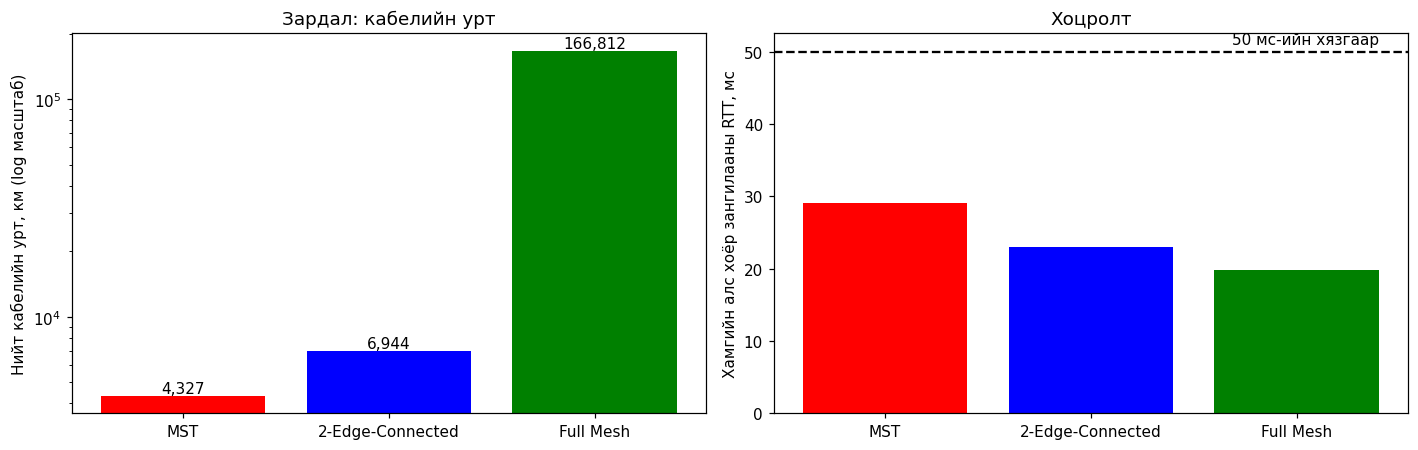

2-Edge-Connected: MST-ээс +60.5% нэмэлт кабель, bridge 0, RTT 23.0 мс (50 мс-ээс бага)
Full Mesh: MST-ээс 3,755% их кабель, 100%-ийн сүлжээ нь хэт үнэтэй


In [15]:
names_t = list(topologies)
colors = ['red', 'blue', 'green']
kms = [total_km(G) for G in topologies.values()]
rtts = [stats(G, base)['rtt_ms'] for G in topologies.values()]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2))
a1.bar(names_t, kms, color=colors)
a1.set_yscale('log'); a1.set_ylabel('Нийт кабелийн урт, км (log масштаб)'); a1.set_title('Зардал: кабелийн урт')
for i, k in enumerate(kms):
    a1.text(i, k, f'{k:,.0f}', ha='center', va='bottom')
a2.bar(names_t, rtts, color=colors)
a2.axhline(50, color='black', ls='--'); a2.text(2.4, 51, '50 мс-ийн хязгаар', ha='right')
a2.set_ylabel('Хамгийн алс хоёр зангилааны RTT, мс'); a2.set_title('Хоцролт')
plt.tight_layout(); plt.show()

s2, sf = stats(two, base), stats(full, base)
print(f"2-Edge-Connected: MST-ээс +{s2['overhead']:.1f}% нэмэлт кабель, bridge {s2['bridges']}, RTT {s2['rtt_ms']:.1f} мс (50 мс-ээс бага)")
print(f"Full Mesh: MST-ээс {sf['overhead']:,.0f}% их кабель, 100%-ийн сүлжээ нь хэт үнэтэй")

### 12. Таны эхний cell-ийн аргыг 22 хотын сүлжээнд хэрэглэх
`composite_weight` нь 0.4 × зай + 0.6 × замын хүндрэл. Хүндрэлийг энд рельефээс тооцсон (1 хамгийн сайн, 5 хамгийн муу).

In [16]:
for weight in ('distance_km', 'composite_weight'):
    path = nx.shortest_path(two, 'Darkhan', 'Khentii', weight=weight)
    length = nx.shortest_path_length(two, 'Darkhan', 'Khentii', weight=weight)
    print(f"{weight:17s}: {' > '.join(mn(n) for n in path)}  (зардал {length:.2f})")

distance_km      : Дархан > Зуунмод > Чойр > Хэнтий  (зардал 663.70)
composite_weight : Дархан > Зуунмод > Чойр > Хэнтий  (зардал 3.57)


### 13. Дүгнэлт
- MST нь бүх хотыг хамгийн бага зардлаар холбосон ч бүх кабель нь bridge тул аль нэг кабель тасрахад сүлжээ тасарна.
- Хамгийн бага өртөгтэй нэмэлт кабелиудыг сонгож нэмэхэд сүлжээ 2-Edge-Connected болж, аль ч нэг кабель тасрахад салахгүй.
- Кабелийн замыг ой, уулыг тойруулан тооцсоноор рельефийн өртөг буурч, замын урт бага зэрэг нэмэгдсэн.
- Full Mesh-тэй харьцуулахад зардал хэд дахин бага, RTT нь 50 мс-ийн хязгаараас хол бага байна.
- *(Өөрийн үр дүнгээр нөхөж бичнэ үү: нэмэлт кабелийн хувь, нөөц замуудын урт.)*